# 4. Who should get the next booklet?

Risk answers "who might leave". Targeting needs "whose spend goes up *because* they got a booklet", the
conditional treatment effect, or uplift. Someone at high risk may not respond at all; a loyal heavy shopper buys
anyway. Three learners are compared (T, X and DR learners, all on LightGBM).

Uplift models can't be checked against labels, because nobody is observed both with and without a booklet.
So there are two checks before anything is used:

1. **Planted effects.** Real households and the real (non-random) targeting, with outcomes simulated from known
   per-household effects. If a learner can't find planted heterogeneity, its real output means nothing.
2. **Out of time.** Train on earlier waves, predict the next one, and compare with what the matched pairs
   actually did.

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display

from couponroi import config
from couponroi.warehouse import connect

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
con = connect()  # read-only DuckDB warehouse built by `couponroi build`
R = lambda name: json.loads((config.RESULTS_DIR / f"{name}.json").read_text())  # noqa: E731
fig = lambda name, width=900: display(Image(filename=str(config.FIG_DIR / f"{name}.png"), width=width))  # noqa: E731
sql = lambda path: (config.SQL_DIR / path).read_text()  # noqa: E731

## Check 1: planted effects

In [2]:
u = R("uplift")
pd.DataFrame(u["semi_synthetic"]).pivot(index="learner", columns="scenario", values="policy_share_of_oracle").round(3)

scenario,randomised (like an A/B test),targeted (like the real booklets)
learner,,
DR-learner,0.677,0.535
T-learner,0.648,0.652
X-learner,0.739,0.738


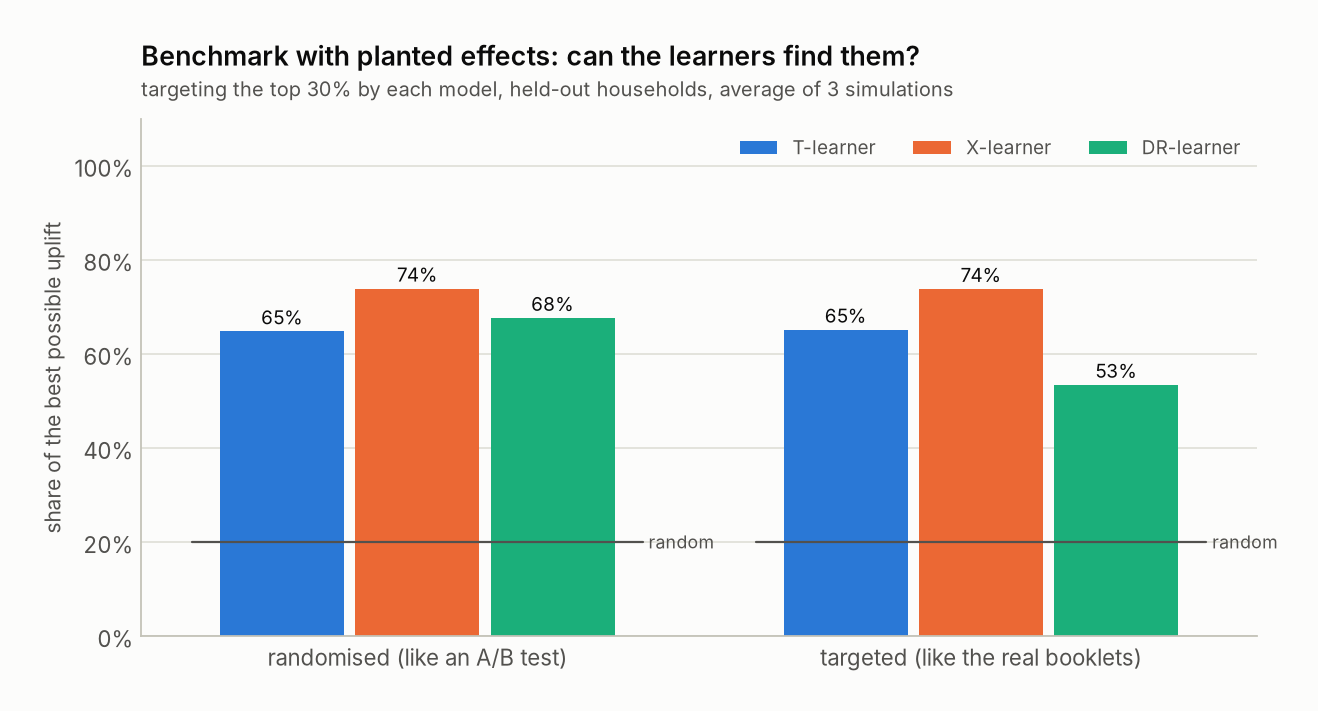

In [3]:
fig('uplift_1_semisynthetic', 820)

Targeting the top 30% by the X-learner captures about three quarters of the best possible uplift, against 20% for
random targeting, even with the real biased assignment. The learner used downstream is the winner of this
benchmark (the rule is in `uplift.choose_learner`), not the winner of the real out-of-time check below, and all
three learners are shown there.

## Check 2: out of time on real waves

In [4]:
pd.DataFrame(u['out_of_time']).round(3)

,learner,slope,slope_se,slope_p,top30_effect,all_effect,top30_gain,top30_gain_lo,top30_gain_hi,n_pairs
0,T-learner,0.230,0.184,0.212,-0.138,0.365,-0.504,-4.604,3.174,641
1,X-learner,0.934,0.364,0.010,4.000,0.365,3.635,-0.404,7.300,641
2,DR-learner,0.221,0.220,0.314,0.465,0.365,0.100,-3.348,3.627,641
3,heaviest shoppers,NaN,NaN,NaN,0.926,0.365,0.560,-3.894,4.756,641
4,random,NaN,NaN,NaN,0.233,0.365,-0.132,-3.586,3.498,641


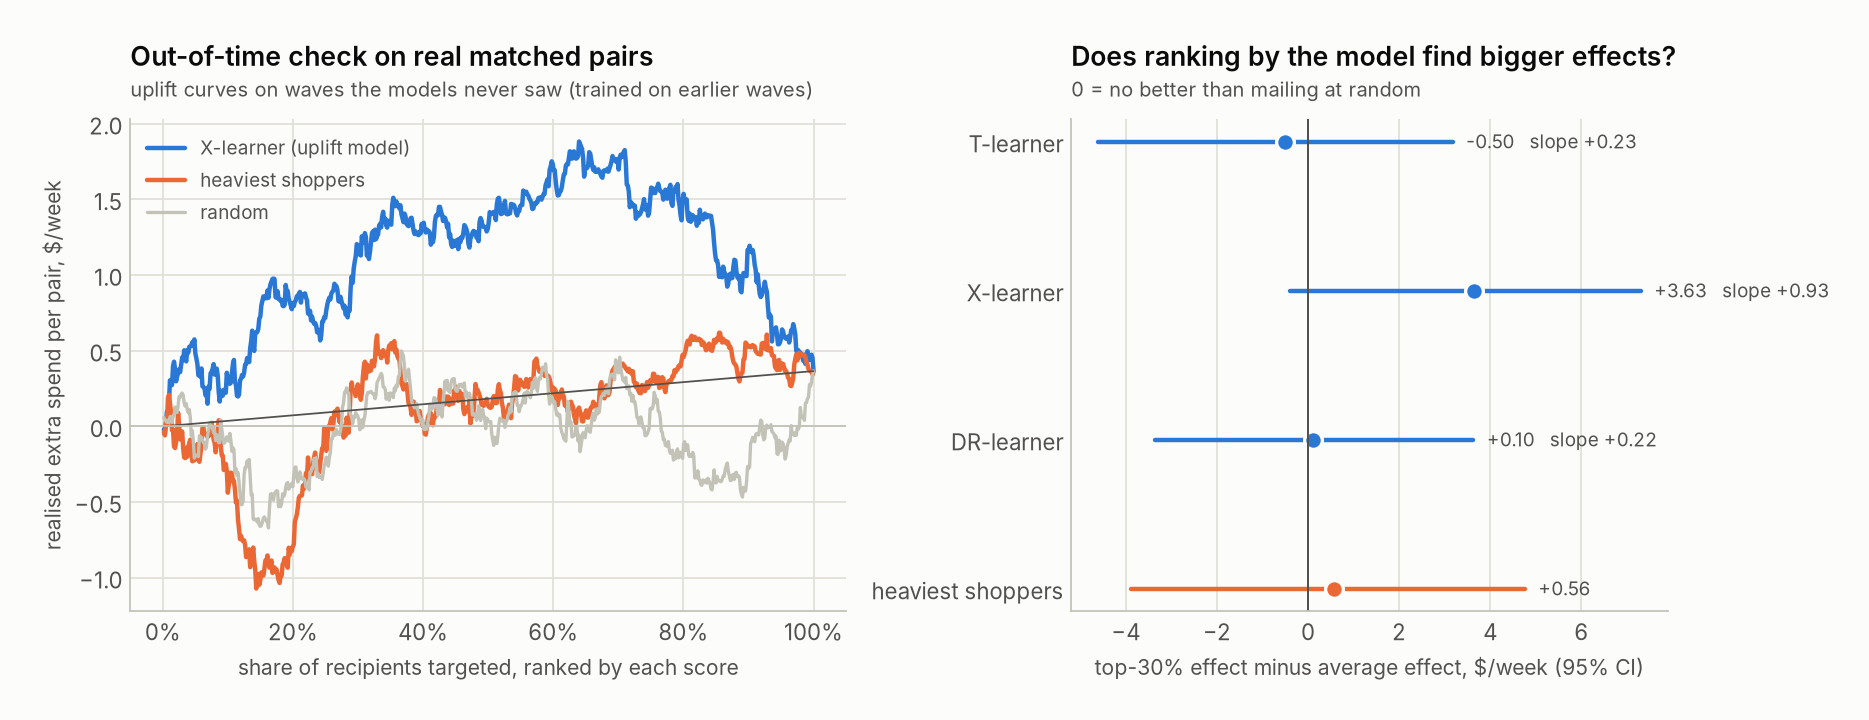

With planted effects and the real (non-random) targeting, the X-learner captured 74% of the best possible uplift in its top 30% (random: 20%). On real held-out waves its predictions had a calibration slope of 0.93 (top-30% gain +3.63 $/week, 95% CI -0.40 to +7.30), so predictions are shrunk toward the average effect before they drive any targeting.

In [5]:
fig('uplift_2_out_of_time', 1000); display(Markdown(u['headline']))

The X-learner's predictions line up with what actually happened (calibration slope near 1 and significant),
while the T and DR learners don't hold up. The top-30% gain is promising but its interval still touches zero,
so predictions are shrunk toward the average effect by the calibration slope before they drive any decision.

## The decision: who to mail, and how many

Expected profit of mailing a household = shrunk uplift x weeks x margin - cost. Mail everyone with positive
expected profit, best first.

In [6]:
pol = R("policy")
display(pd.Series(pol["profit_at_budget"]).rename("simulated profit at current budget").to_frame())
display(Markdown(pol["headline"]))

,simulated profit at current budget
uplift model,"6,559.294"
heaviest shoppers (current rule),"1,050.973"
highest lapse risk,"1,535.488"
random,85.579


Simulated: at the current budget (45% of active households) the uplift ranking is worth $6.6K vs $1.1K for the heaviest-shopper rule and $86 at random. Mailing only the 1,057 households with positive expected profit (47%) gives $6.6K (range $2.7K to $10.5K across the effect's 95% CI). Best ranking at budget: uplift model.

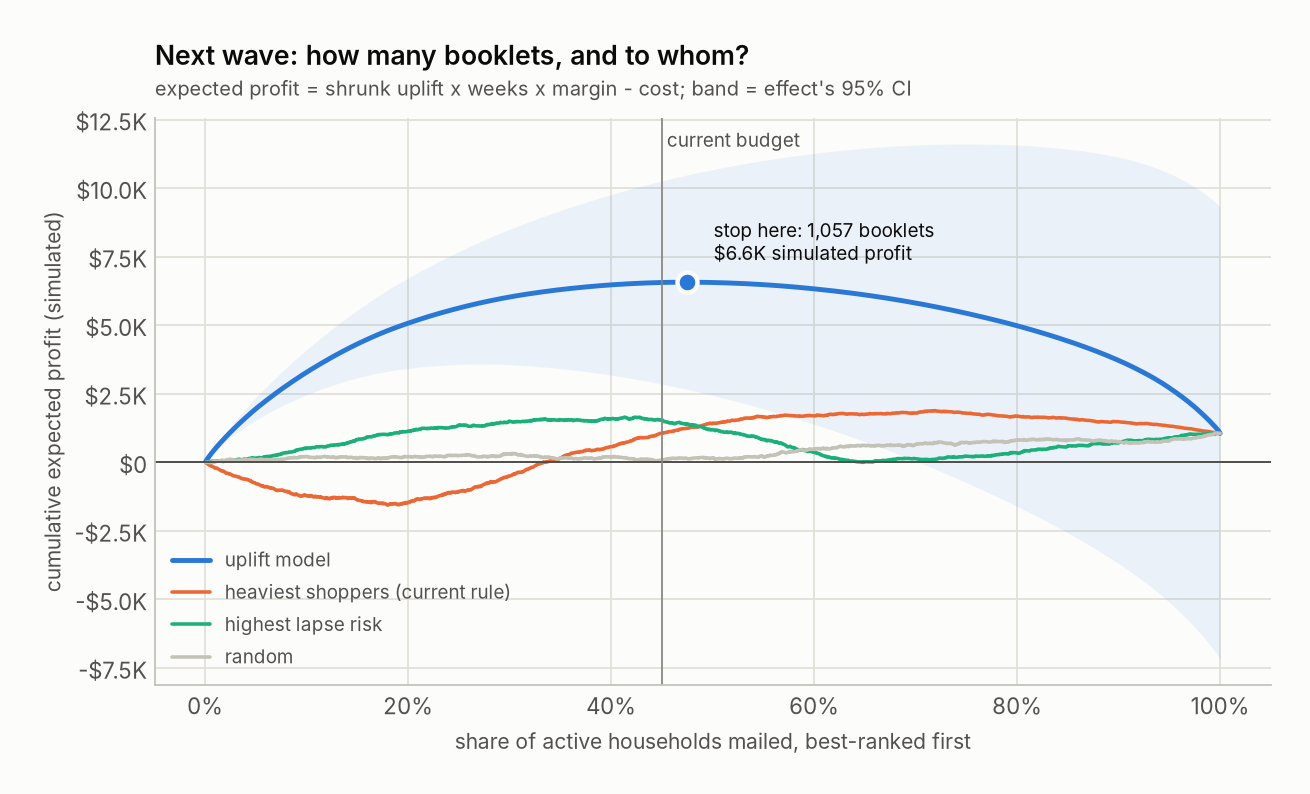

In [7]:
fig('policy_1_expected_profit', 820)

That curve scores every ranking with the model's own estimates, so the model wins by construction. The honest
version uses held-out waves and what the matched pairs actually spent:

In [8]:
hold = pd.DataFrame({"top 30% of the list": pol["holdout_profit_per_1000_at_30pct"],
                     "everyone": pol["holdout_profit_per_1000_all"]})
(hold / pd.Series({"top 30% of the list": 300, "everyone": 1000})).round(2).rename(
    columns=lambda c: f"{c}: profit per booklet ($, simulated)")

,"top 30% of the list: profit per booklet ($, simulated)","everyone: profit per booklet ($, simulated)"
uplift model,6.610,-0.760
heaviest shoppers (current rule),0.380,-0.760
random,-1.020,-0.760


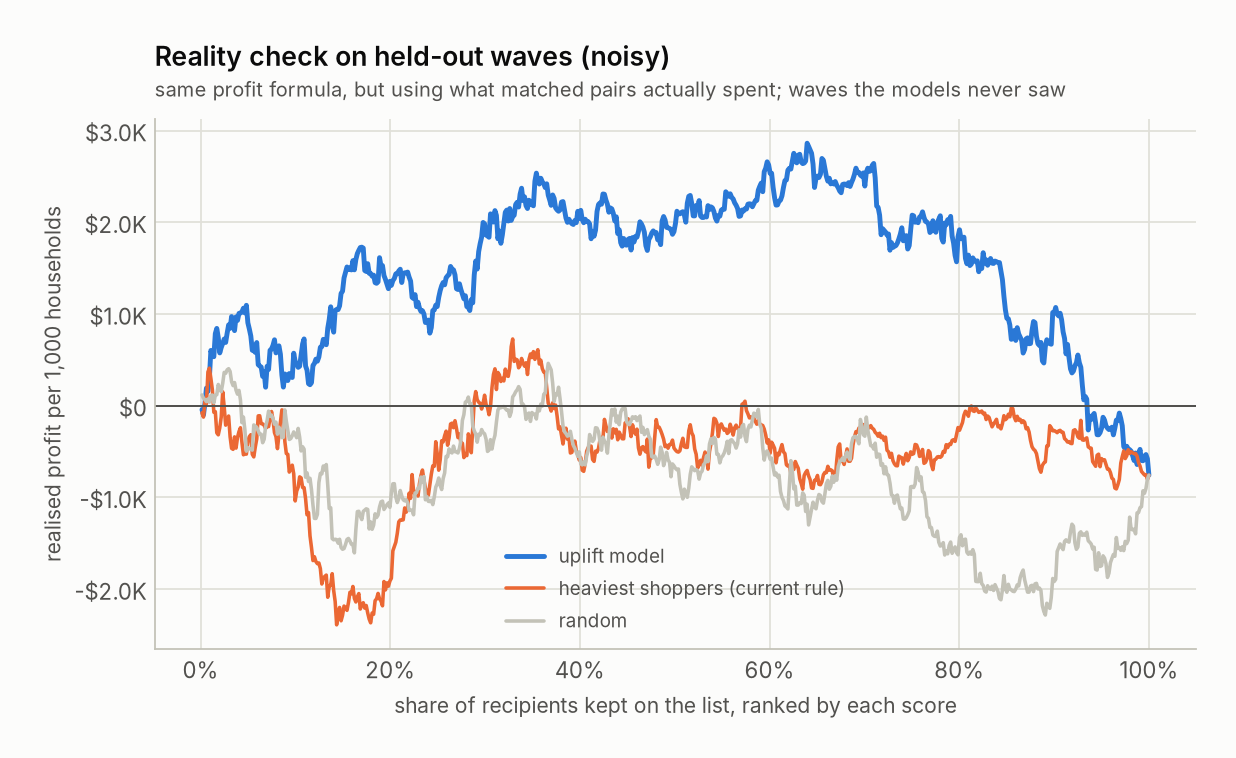

In [9]:
fig('policy_2_holdout_profit', 760)

## How sensitive is this to the assumptions?

In [10]:
s = pd.DataFrame(pol["sensitivity"])
s.pivot(index="margin", columns="cost", values="share_to_mail").round(2)

cost,0.500,1.000,1.500,2.000,3.000
margin,,,,,
0.200,0.530,0.480,0.440,0.390,0.310
0.250,0.540,0.500,0.460,0.430,0.350
0.280,0.550,0.510,0.470,0.440,0.380
0.300,0.550,0.510,0.480,0.450,0.390
0.350,0.560,0.520,0.490,0.470,0.420


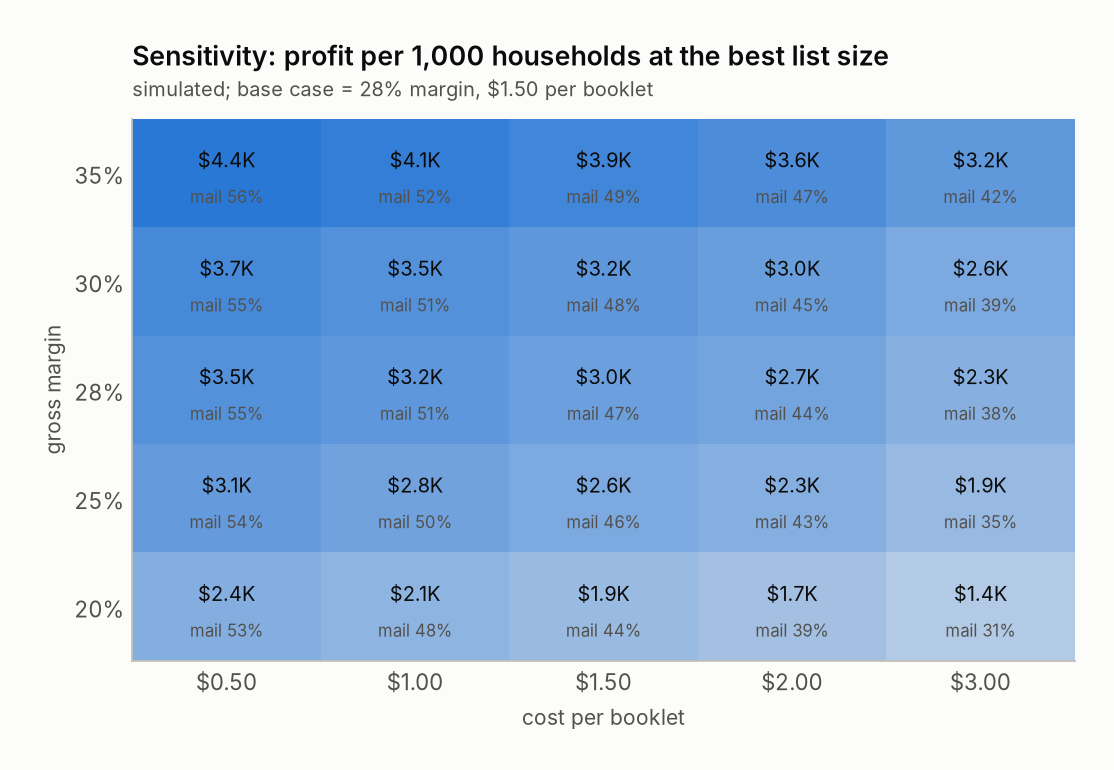

In [11]:
fig('policy_3_sensitivity', 700)

## The output a CRM team would use

In [12]:
pd.read_csv(config.RESULTS_DIR / 'next_wave_mailing_list.csv').head(10)

,household_id,uplift,expected_profit,lapse_prob,spend_16w
0,385,14.669,28.279,0.242,59.839
1,138,13.335,25.570,0.074,57.591
2,492,13.039,24.969,0.016,79.942
3,1085,12.901,24.688,0.130,44.364
4,77,12.821,24.528,0.144,53.221
5,1437,12.636,24.151,NaN,38.519
6,931,12.247,23.361,NaN,47.191
7,1980,12.235,23.337,0.136,57.451
8,1798,12.124,23.111,NaN,31.884
9,777,12.018,22.897,0.048,86.624


## What I'd do next

* Run the next wave as an experiment: target by uplift, keep a random holdout in every wave, pool the holdouts.
  That turns this observational estimate into a measured one and gives clean data to retrain the uplift model.
* Add real margins by category (coupons on high-margin categories are worth more).
* Retrain the lapse model monthly and watch the drift report.